In [379]:
import os
import sys
sys.path.append(r"C:\Users\acostamendoza\projects\distance-project")
from path_setup import setup_project_path
setup_project_path()
from src.utils import create_new_result_dir
from src.LinearExperiment import LinearDevice, LinearPlots
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from suite2p.extraction import dcnv
from src.ActivityPipelines import ActivityLoader
from scipy.ndimage import gaussian_filter1d

%load_ext autoreload
%autoreload 2

colors = ['orange', '#35b779', '#31688e', '#440154', 'gray']
mouse_name = 'SAM032'
record_date = '250430'
experiment_name = 'linear-device'

data_dir = r'D:/data-distance-coding-project/processed-data/{record_date}_{mouse_name}_{experiment_name}/'.format(record_date=record_date, mouse_name=mouse_name, experiment_name=experiment_name)

if not os.path.exists(data_dir):
    raise FileNotFoundError(f"The directory {data_dir} does not exist.")
else:
    print(f"The directory {data_dir} exists.")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
The directory D:/data-distance-coding-project/processed-data/250430_SAM032_linear-device/ exists.


In [187]:
L = LinearDevice(data_dir, response_mode='spikes-zscore', tau=2)

Directory results already exists
Computing spike deconvolution with tau = 2
Successfully loaded activity data
Stimulus file found
Synchronized stimulus and activity
Repeat stimulus on length distribution:
    88 repeats have length 41
    8 repeats have length 42
Set stimulus on length: 41


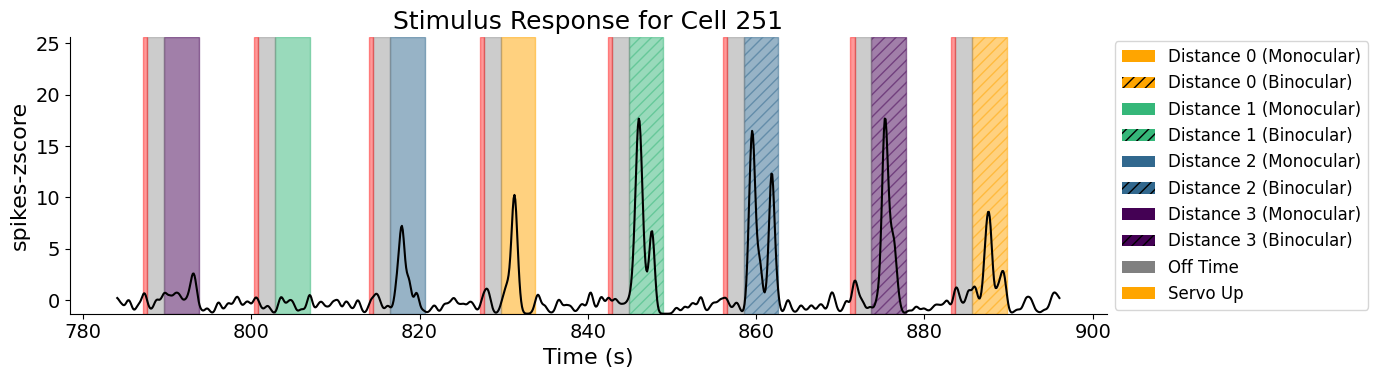

In [405]:
cell_to_show = 251
LinearPlots(L).plot_stimulus_response(repeats=[56,64], cell = cell_to_show)

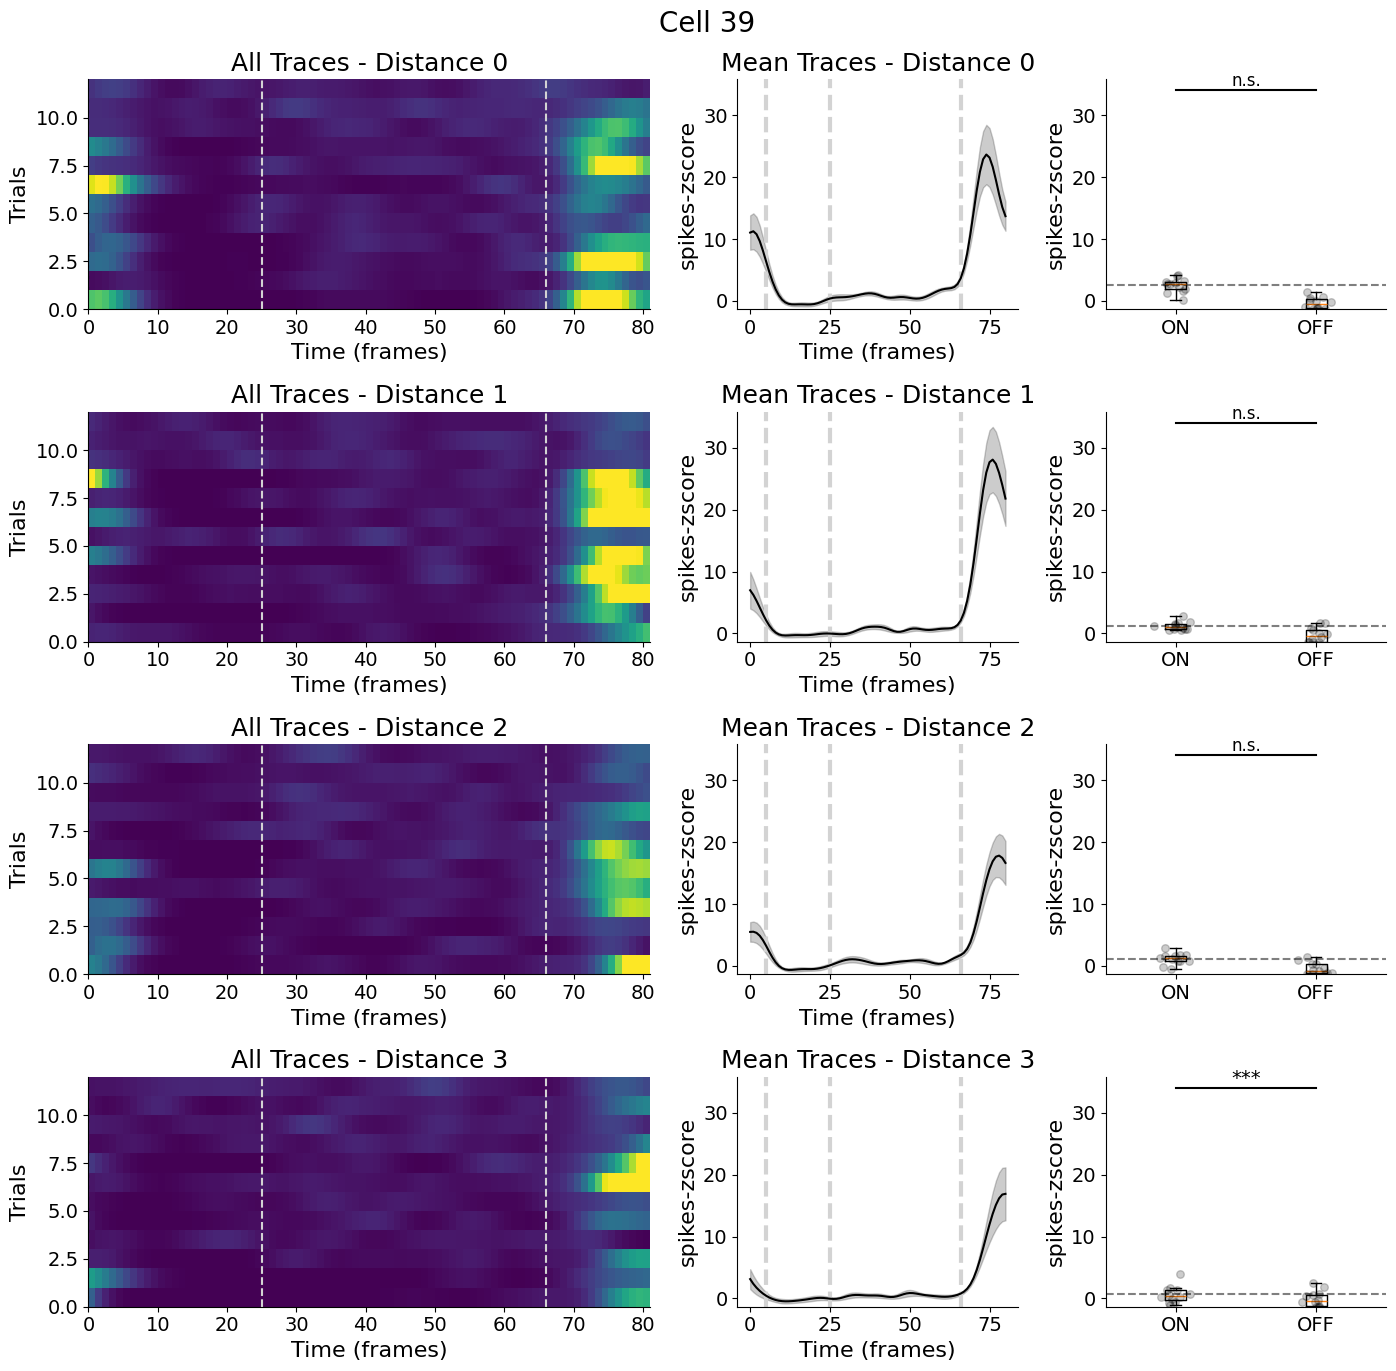

In [191]:
cell_to_show = 39
fig = LinearPlots(L).plot_all_traces_colormap(cell=cell_to_show, pre_time=2500, post_time=1500, distance=[0, 1, 2, 3], monocular=False)

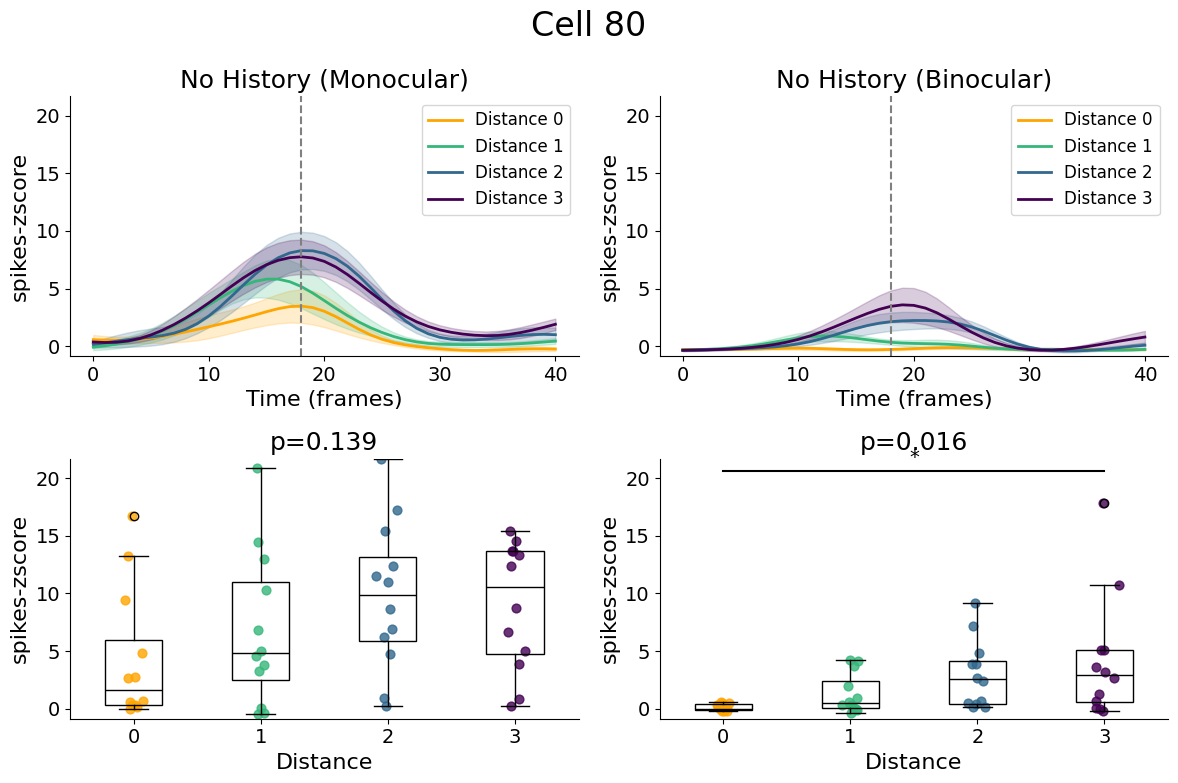

In [204]:
cell_to_show = 80
fig = LinearPlots(L).plot_distance_and_rf_comparison(cell=cell_to_show)

In [89]:
# for all cells, plot both and save them to results
results_path = create_new_result_dir(data_dir, r'response-comparison')

for cell_to_show in L.suite2p_id:
    fig = LinearPlots(L).plot_all_traces_colormap(cell=cell_to_show, pre_time=2500, post_time=1500)
    plt.savefig(os.path.join(results_path, f'cell_{cell_to_show}_all_traces.png'))
    plt.close(fig)
    fig = LinearPlots(L).plot_distance_and_rf_comparison(cell=cell_to_show)
    plt.savefig(os.path.join(results_path, f'cell_{cell_to_show}_distance_and_rf.png'))
    plt.close(fig)

Creating directory: response-comparison


# Now for responsivness

In [409]:
# Initialize counters for responsive cells
responsive_all = []
responsive_monocular = []
responsive_binocular = []

# Analyze each cell
for cell in (L.suite2p_id):
    is_responsive_monocular = L.analyze_cell_responsiveness(cell, monocular=True)[0]
    is_responsive_binocular = L.analyze_cell_responsiveness(cell, monocular=False)[0]
    
    # Count responsive cells
    if is_responsive_monocular or is_responsive_binocular:
        responsive_all.append(cell)

    if is_responsive_monocular:
        responsive_monocular.append(cell)

    if is_responsive_binocular:
        responsive_binocular.append(cell)


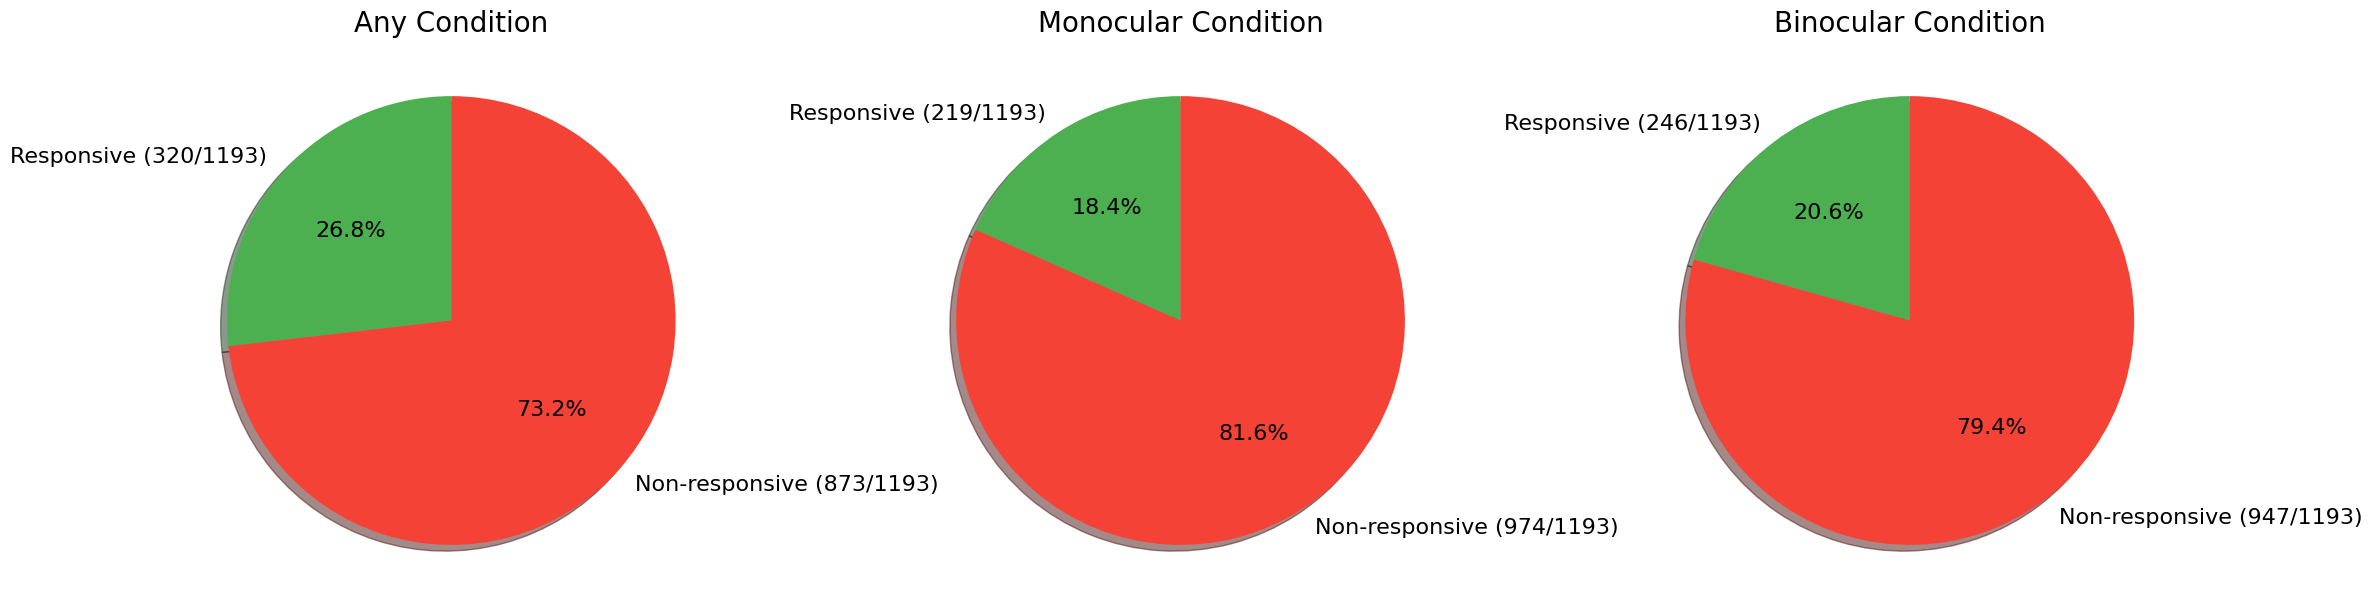

In [410]:
# Create pie charts for each condition
# Create a larger figure with more space for the pie charts
fig, axes = plt.subplots(1, 3, figsize=(24, 16))

# Data for pie charts
conditions = ['Any', 'Monocular', 'Binocular']
responsive_counts = [len(responsive_all), len(responsive_monocular), len(responsive_binocular)]
non_responsive_counts = [len(L.suite2p_id) - count for count in responsive_counts]

# Create pie charts with larger text and elements
for i, (condition, responsive, non_responsive) in enumerate(zip(conditions, responsive_counts, non_responsive_counts)):
    axes[i].pie([responsive, non_responsive], 
                labels=[f'Responsive ({responsive}/{len(L.suite2p_id)})', f'Non-responsive ({non_responsive}/{len(L.suite2p_id)})'],
                autopct='%1.1f%%',
                colors=['#4CAF50', '#F44336'],
                startangle=90,
                shadow=True,
                textprops={'fontsize': 16})
    axes[i].set_title(f'{condition} Condition', fontsize=20)

plt.tight_layout()
plt.subplots_adjust(wspace=0.3)  # Add more space between subplots
plt.show()

True 1.663083688877009
0.01564503052933187 3 0.9400130132889206


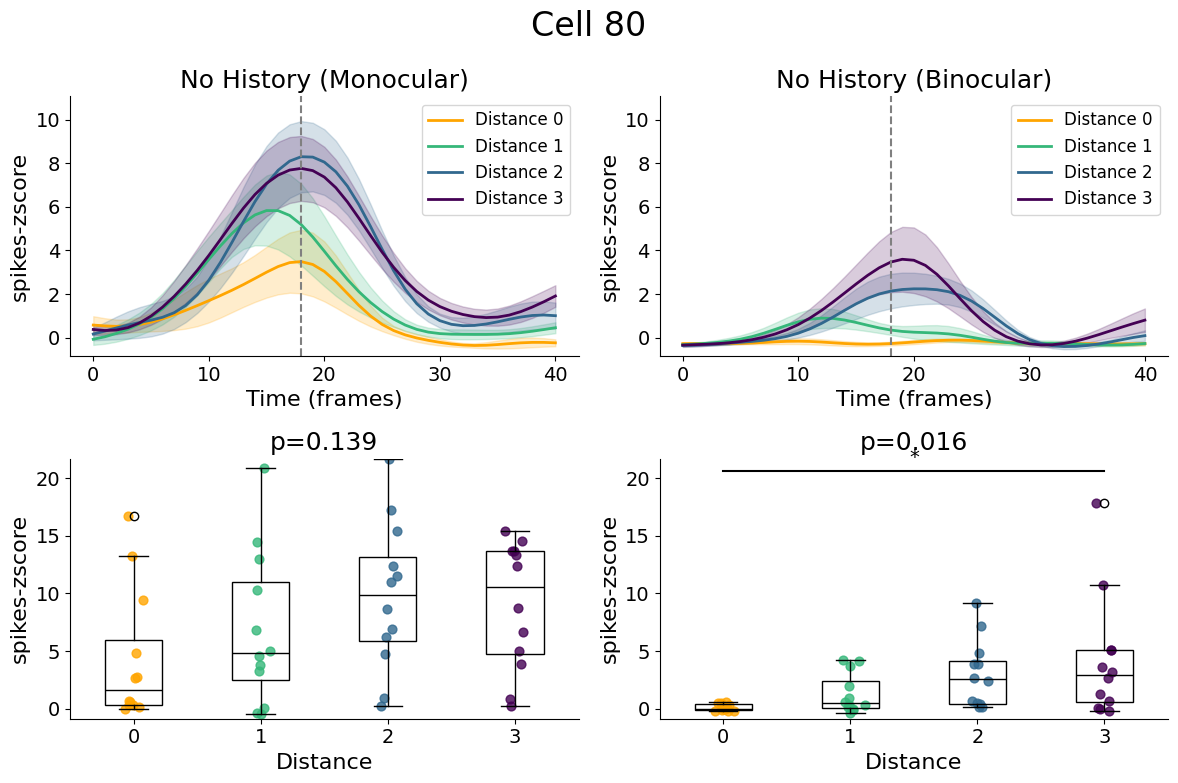

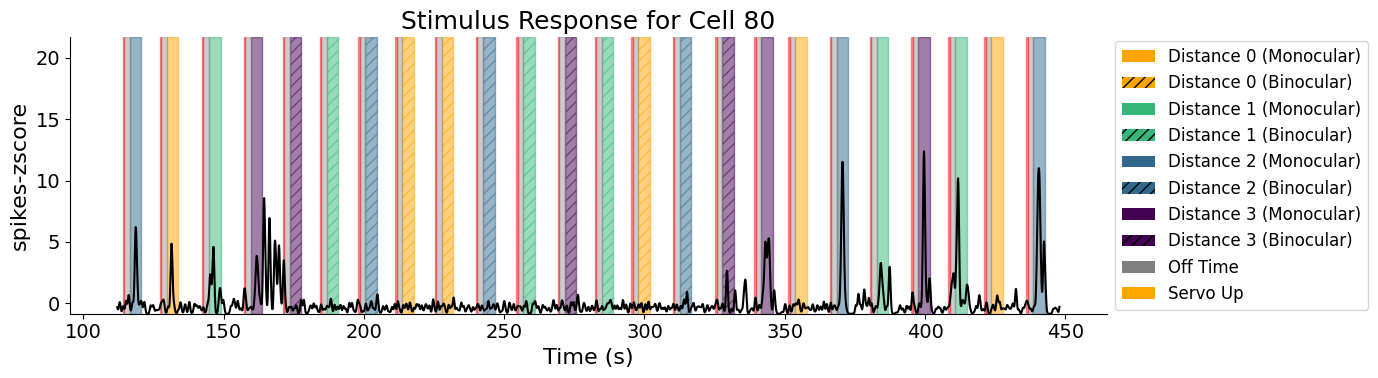

In [300]:
cell_to_show = 80
is_responsive, on_max, off_max = L.analyze_cell_responsiveness(cell=cell_to_show, monocular=False)
print(is_responsive, np.percentile(on_max, 75))

p_value, preferred_distance, modulation_strength, rf_values = L.analyze_cell_modulation(cell=cell_to_show, monocular=False)
print(p_value, preferred_distance, modulation_strength)

fig = LinearPlots(L).plot_distance_and_rf_comparison(cell=cell_to_show)
fig= LinearPlots(L).plot_stimulus_response(repeats=[8,32], cell = cell_to_show)

In [415]:
stats = L.analyze_population_stats()


Total cells: 1193
Responsive cells (either condition): 320 (26.8%)
Monocular modulated cells: 14 (4.4% of responsive, 1.2% of total)
Binocular modulated cells: 55 (17.2% of responsive, 4.6% of total)
Both modulated cells: 2 (0.6% of responsive, 0.2% of total)


In [308]:
stats.head()

,cell_id,mono_responsive,mono_modulated,mono_modulated_p,mono_pref,mono_strength,bino_responsive,bino_modulated,bino_modulated_p,bino_pref,bino_strength
0,0,False,False,0.779496,NaN,NaN,False,False,0.214455,NaN,NaN
1,1,True,False,0.411411,NaN,NaN,True,False,0.664850,NaN,NaN
2,2,False,False,0.222069,NaN,NaN,False,False,0.278793,NaN,NaN
3,3,False,False,0.495657,NaN,NaN,False,False,0.006545,NaN,NaN
4,4,False,False,0.919339,NaN,NaN,False,False,0.155570,NaN,NaN


Total responsive cells: 320
Monocular modulated only: 14
Binocular modulated only: 55
Both conditions modulated: 2
Responsive but not modulated: 249


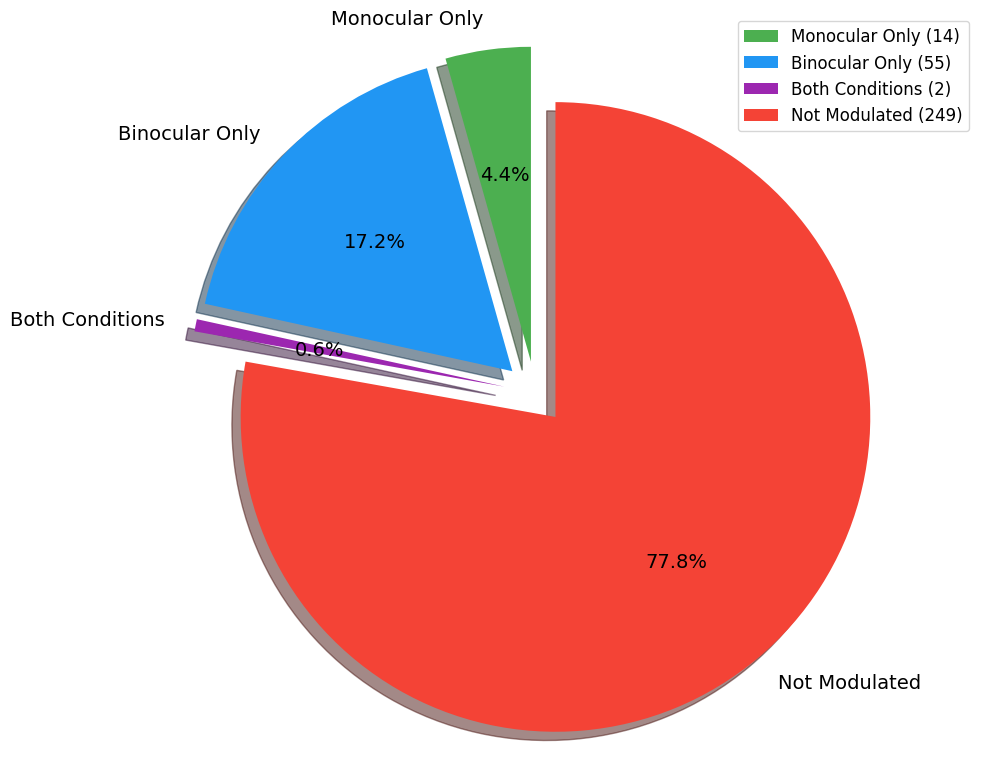

In [320]:
# Extract data for analysis
responsive_cells = stats[(stats['mono_responsive'] == True) | (stats['bino_responsive'] == True)]
responsive_cell_ids = responsive_cells['cell_id'].values

# Categorize cells
monocular_only = responsive_cells[(responsive_cells['mono_modulated'] == True) & 
                                 (responsive_cells['bino_modulated'] == False)]['cell_id'].values

binocular_only = responsive_cells[(responsive_cells['mono_modulated'] == False) & 
                                 (responsive_cells['bino_modulated'] == True)]['cell_id'].values

both_modulated = responsive_cells[(responsive_cells['mono_modulated'] == True) & 
                                 (responsive_cells['bino_modulated'] == True)]['cell_id'].values

non_modulated = responsive_cells[(responsive_cells['mono_modulated'] == False) & 
                                (responsive_cells['bino_modulated'] == False)]['cell_id'].values

# Print summary
print(f"Total responsive cells: {len(responsive_cell_ids)}")
print(f"Monocular modulated only: {len(monocular_only)}")
print(f"Binocular modulated only: {len(binocular_only)}")
print(f"Both conditions modulated: {len(both_modulated)}")
print(f"Responsive but not modulated: {len(non_modulated)}")

# Create pie chart of modulation categories
fig, ax = plt.subplots(figsize=(10, 8))

# Data for pie chart
labels = ['Monocular Only', 'Binocular Only', 'Both Conditions', 'Not Modulated']
sizes = [len(monocular_only), len(binocular_only), len(both_modulated), len(non_modulated)]
colors = ['#4CAF50', '#2196F3', '#9C27B0', '#F44336']
explode = (0.1, 0.1, 0.1, 0.1)  # explode all slices for better visibility

# Create pie chart
ax.pie(sizes, explode=explode, labels=labels, colors=colors,
       autopct='%1.1f%%', shadow=True, startangle=90, textprops={'fontsize': 14})
ax.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle


# Add legend with counts
legend_labels = [f'{label} ({count})' for label, count in zip(labels, sizes)]
ax.legend(legend_labels, loc='best', fontsize=12)

plt.tight_layout()
plt.show()

# For use in subsequent cells
monocular_modulated = np.concatenate([monocular_only, both_modulated])
binocular_modulated = np.concatenate([binocular_only, both_modulated])
responsive_all = responsive_cell_ids

C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_32032\886995608.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(box_data, patch_artist=True, labels=box_labels, showfliers=False)


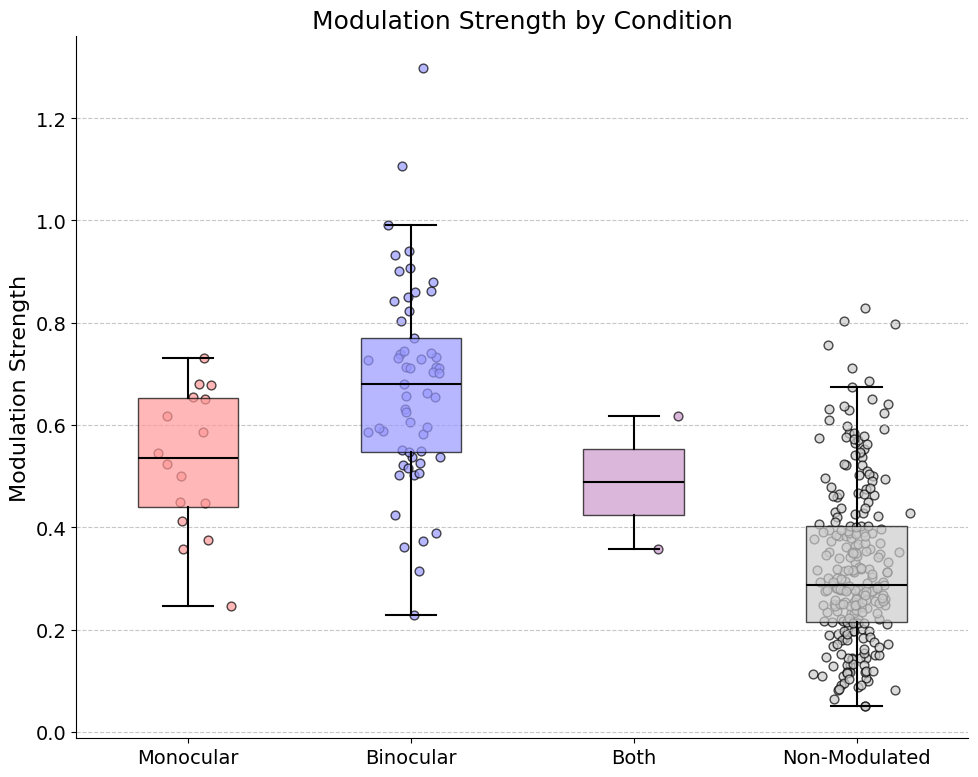

In [413]:
# Create a boxplot of modulation strength for monocular, binocular, both conditions, and non-modulated
fig, ax = plt.subplots(figsize=(10, 8))

# Prepare data for boxplot
mono_strength = stats['mono_strength'].dropna()
bino_strength = stats['bino_strength'].dropna()
both_strength = stats.loc[stats['mono_modulated'] & stats['bino_modulated'], 'mono_strength'].dropna()

# Get IDs of non-modulated cells (responsive but not modulated)
non_mod_ids = stats.loc[(stats['mono_responsive'] | stats['bino_responsive']) & 
                        ~stats['mono_modulated'] & ~stats['bino_modulated'], 'cell_id'].values

# Get the both_strength for these non-modulated cells
non_mod_strength = stats.loc[stats['cell_id'].isin(non_mod_ids), 'both_strength'].dropna()

# Create boxplot
box_data = [mono_strength, bino_strength, both_strength, non_mod_strength]
box_labels = ['Monocular', 'Binocular', 'Both', 'Non-Modulated']
box_colors = ['#FF9999', '#9999FF', '#CC99CC', '#CCCCCC']

bp = ax.boxplot(box_data, patch_artist=True, labels=box_labels, showfliers=False)

# Customize boxplot appearance
for i, box in enumerate(bp['boxes']):
    box.set(facecolor=box_colors[i], alpha=0.7)
    
for element in ['whiskers', 'caps', 'medians']:
    plt.setp(bp[element], color='black', linewidth=1.5)

# Add individual points with jitter
for i, data in enumerate(box_data):
    # Create jitter effect
    x = np.random.normal(i+1, 0.08, size=len(data))
    ax.scatter(x, data, alpha=0.7, s=40, color=box_colors[i], edgecolor='black')

# Add labels and title
ax.set_ylabel('Modulation Strength')
ax.set_title('Modulation Strength by Condition')
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Show plot
plt.tight_layout()
plt.show()

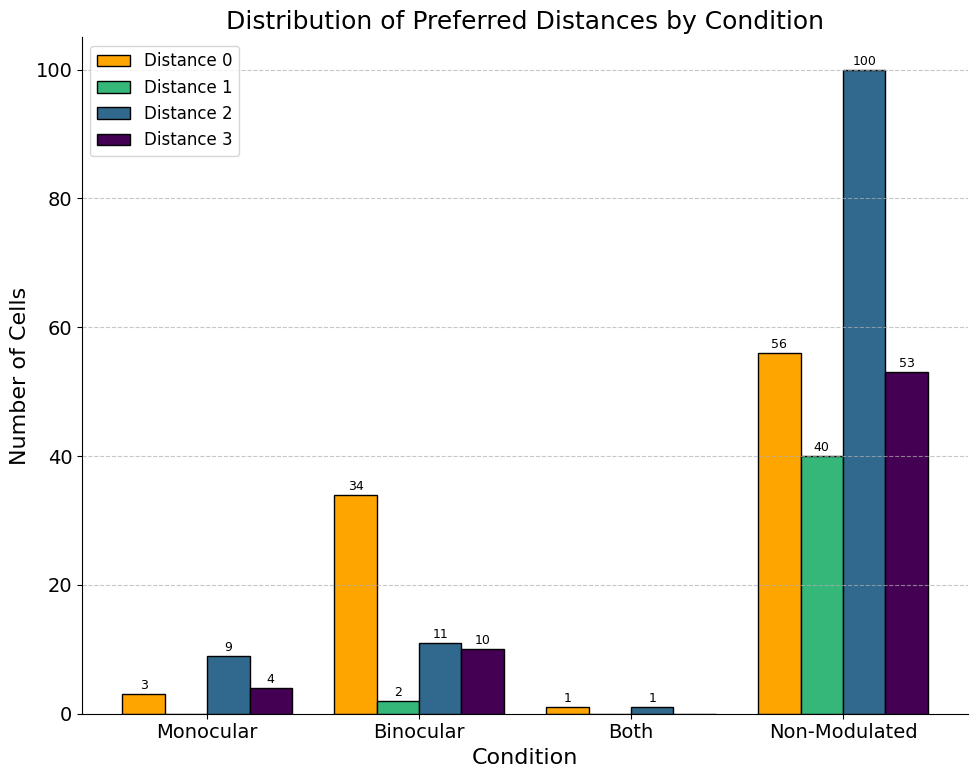

In [426]:
# plot a barplot of the preferred distance distribution for each condition
fig, ax = plt.subplots(figsize=(10, 8))

# Prepare data for barplot
# Get preferred distances for each condition
mono_pref = stats.loc[stats['mono_modulated'], 'mono_pref'].dropna()
bino_pref = stats.loc[stats['bino_modulated'], 'bino_pref'].dropna()
both_pref_mono = stats.loc[stats['mono_modulated'] & stats['bino_modulated'], 'mono_pref'].dropna()

# for the non modulated, get the both_pref
non_mod_ids = stats.loc[(stats['mono_responsive'] | stats['bino_responsive']) & 
                        ~stats['mono_modulated'] & ~stats['bino_modulated'], 'cell_id'].values
non_mod_pref = stats.loc[stats['cell_id'].isin(non_mod_ids), 'both_pref'].dropna()

# Calculate counts for each distance in each condition
distances = [0, 1, 2, 3]
conditions = ['Monocular', 'Binocular', 'Both', 'Non-Modulated']

# Count cells for each distance
mono_counts = [sum(mono_pref == d) for d in distances]
bino_counts = [sum(bino_pref == d) for d in distances]
both_counts_mono = [sum(both_pref_mono == d) for d in distances]
non_mod_counts = [sum(non_mod_pref == d) for d in distances]

# Set width of bars
bar_width = 0.2
r1 = np.arange(len(conditions))
r2 = [x + bar_width for x in r1]
r3 = [x + bar_width for x in r2]
r4 = [x + bar_width for x in r3]

# Create grouped bar plot
ax.bar(r1, [mono_counts[0], bino_counts[0], both_counts_mono[0], non_mod_counts[0]], width=bar_width, color=colors[0], edgecolor='black', label=f'Distance {distances[0]}')
ax.bar(r2, [mono_counts[1], bino_counts[1], both_counts_mono[1], non_mod_counts[1]], width=bar_width, color=colors[1], edgecolor='black', label=f'Distance {distances[1]}')
ax.bar(r3, [mono_counts[2], bino_counts[2], both_counts_mono[2], non_mod_counts[2]], width=bar_width, color=colors[2], edgecolor='black', label=f'Distance {distances[2]}')
ax.bar(r4, [mono_counts[3], bino_counts[3], both_counts_mono[3], non_mod_counts[3]], width=bar_width, color=colors[3], edgecolor='black', label=f'Distance {distances[3]}')

# Add labels and title
ax.set_ylabel('Number of Cells')
ax.set_xlabel('Condition')
ax.set_title('Distribution of Preferred Distances by Condition')
ax.set_xticks([r + 1.5 * bar_width for r in range(len(conditions))])
ax.set_xticklabels(conditions)
ax.legend()

# Add cell counts as text above each bar
for i, r in enumerate([r1, r2, r3, r4]):
    for j, count in enumerate([mono_counts[i], bino_counts[i], both_counts_mono[i], non_mod_counts[i]]):
        if count > 0:
            ax.text(r[j], count + 0.3, f'{count}', ha='center', va='bottom', fontsize=9)

# Add grid for better readability
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [323]:
# Create directories for each category
monocular_dir = create_new_result_dir(data_dir, r'monocular_only')
binocular_dir = create_new_result_dir(data_dir, r'binocular_only')
both_dir = create_new_result_dir(data_dir, r'both_modulated')
non_modulated_dir = create_new_result_dir(data_dir, r'non_modulated')

# Plot cells from stats DataFrame by category
for _, row in stats.iterrows():
    cell = row['cell_id']
    
    # Monocular only modulated cells
    if row['mono_modulated'] and not row['bino_modulated']:
        fig = LinearPlots(L).plot_all_traces_colormap(cell=cell, monocular=True)
        fig.savefig(os.path.join(monocular_dir, f'cell_{cell}_monocular.png'))
        plt.close(fig)
        fig = LinearPlots(L).plot_distance_and_rf_comparison(cell=cell)
        fig.savefig(os.path.join(monocular_dir, f'cell_{cell}_monocular_rf.png'))
        plt.close(fig)
    
    # Binocular only modulated cells
    elif not row['mono_modulated'] and row['bino_modulated']:
        fig = LinearPlots(L).plot_all_traces_colormap(cell=cell, monocular=False)
        fig.savefig(os.path.join(binocular_dir, f'cell_{cell}_binocular.png'))
        plt.close(fig)
        fig = LinearPlots(L).plot_distance_and_rf_comparison(cell=cell)
        fig.savefig(os.path.join(binocular_dir, f'cell_{cell}_binocular_rf.png'))
        plt.close(fig)
    
    # Both conditions modulated cells
    elif row['mono_modulated'] and row['bino_modulated']:
        fig = LinearPlots(L).plot_all_traces_colormap(cell=cell, monocular=None)
        fig.savefig(os.path.join(both_dir, f'cell_{cell}_both.png'))
        plt.close(fig)
        fig = LinearPlots(L).plot_distance_and_rf_comparison(cell=cell)
        fig.savefig(os.path.join(both_dir, f'cell_{cell}_both_rf.png'))
        plt.close(fig)
    
    # Non-modulated but responsive cells
    elif (row['mono_responsive'] or row['bino_responsive']) and not (row['mono_modulated'] or row['bino_modulated']):
        fig = LinearPlots(L).plot_all_traces_colormap(cell=cell, monocular=None)
        fig.savefig(os.path.join(non_modulated_dir, f'cell_{cell}_non_modulated.png'))
        plt.close(fig)
        fig = LinearPlots(L).plot_distance_and_rf_comparison(cell=cell)
        fig.savefig(os.path.join(non_modulated_dir, f'cell_{cell}_non_modulated_rf.png'))
        plt.close(fig)

Creating directory: monocular_only
Creating directory: binocular_only
Creating directory: both_modulated
Creating directory: non_modulated


Number of binocular modulated cells: 57
Cell indices: [np.int64(28), np.int64(80), np.int64(105), np.int64(114), np.int64(149), np.int64(187), np.int64(189), np.int64(196), np.int64(204), np.int64(250), np.int64(278), np.int64(293), np.int64(296), np.int64(318), np.int64(320), np.int64(335), np.int64(384), np.int64(397), np.int64(404), np.int64(458), np.int64(462), np.int64(472), np.int64(483), np.int64(490), np.int64(492), np.int64(510), np.int64(518), np.int64(524), np.int64(525), np.int64(526), np.int64(551), np.int64(559), np.int64(603), np.int64(644), np.int64(653), np.int64(693), np.int64(695), np.int64(710), np.int64(745), np.int64(779), np.int64(794), np.int64(815), np.int64(817), np.int64(915), np.int64(928), np.int64(944), np.int64(969), np.int64(994), np.int64(1090), np.int64(1145), np.int64(1158), np.int64(1165), np.int64(1168), np.int64(1179), np.int64(1187), np.int64(1188), np.int64(1189)]


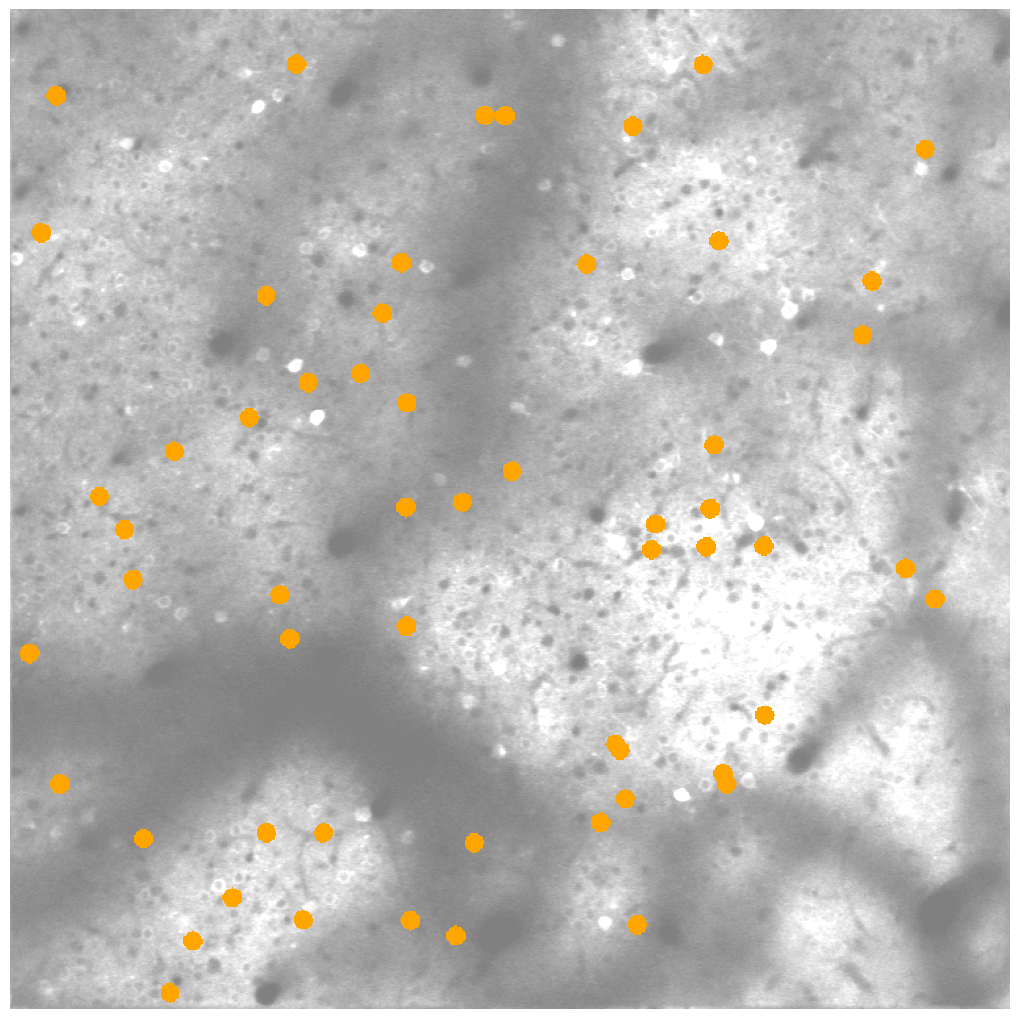

In [378]:
# Load the stat and ops files from the current folder
stat = np.load(L.activity_path + r'\stat.npy', allow_pickle=True)
ops = np.load(L.activity_path + r'\ops.npy', allow_pickle=True).item()

im = np.zeros((ops['Ly'], ops['Lx']))

# Get binocular modulated cells from stats DataFrame
bino_modulated_cells = stats[stats['bino_modulated'] == True]['cell_id'].values
bino_modulated_cells_idx = [np.where(L.suite2p_id == cell_id)[0][0] for cell_id in bino_modulated_cells]

print(f"Number of binocular modulated cells: {len(bino_modulated_cells)}")
print(f"Cell indices: {bino_modulated_cells_idx}")

# Define color map for preferred distances
colors = ['#440154', '#31688e', '#35b779', 'orange']  # Using the color palette from utils.setup_plot_style()
distances = [0, 1, 2, 3]

# Create a colormap for visualization
import matplotlib.colors as mcolors
# Create a discrete colormap where each color corresponds to a specific distance
cmap = mcolors.ListedColormap(colors)
norm = mcolors.BoundaryNorm(boundaries=np.arange(len(distances)+1), ncolors=len(colors))

for cell_id in bino_modulated_cells:
    # Get the preferred distance from stats DataFrame
    pref_distance = stats.loc[stats['cell_id'] == cell_id, 'bino_pref'].values[0]

    # Find the index in suite2p
    idx = np.where(L.suite2p_id == cell_id)[0][0]

    ypix = stat[idx]['ypix'][~stat[idx]['overlap']]
    xpix = stat[idx]['xpix'][~stat[idx]['overlap']]

    # Calculate center of the cell
    center_y = np.mean(ypix)
    center_x = np.mean(xpix)

    # Create a circle mask with radius 8
    y, x = np.ogrid[:ops['Ly'], :ops['Lx']]
    dist_from_center = np.sqrt((x - center_x)**2 + (y - center_y)**2)
    circle_mask = dist_from_center <= 8

    # Add the circle to the image with the color value
    # Map the preferred distance to the corresponding color index (0-3 for the 4 distances)
    distance_index = np.where(distances == pref_distance)[0][0]
    im[circle_mask] = 0.8  # Normalize to 0-1 range for colormap

    
mean_img = ops['meanImg']
vmin = np.percentile(mean_img, 1)
vmax = np.percentile(mean_img, 99)

# Create the figure for display
plt.figure(figsize=(10, 10))
plt.imshow(ops['refImg'], alpha=0.5, cmap='gray', vmin=vmin, vmax=vmax)
# Create a mask for non-zero values
mask = im >= 0
# Create a masked array where zeros are masked out
masked_im = np.ma.masked_where(im == 0, im)

plt.imshow(masked_im, alpha=1, vmin=0, vmax=1, cmap=cmap)
plt.axis('off')  # Turn off axes
plt.tight_layout(pad=0)  # Remove padding
